# 12장 질의 근거 생성

엔트로피는 왜 그 샘플을 골랐는지 말하지 못한다. 이 장은 고른 샘플마다 Jev가 「이 문장의 라벨이 필요한 가장 큰 이유」를 다섯 가지 근거 유형 가운데서 판정하게 하고, 그 판정을 근거 로그로 쌓는다. Jev는 이유를 문장으로 쓰지 않으므로 근거는 유형별 확률로 남는다. 그다음 근거 유형별로 그 샘플들이 학생 모델을 얼마나 개선했는지 재고, 근거가 사실과 맞는지 감사한다.

- 12.1 선택 근거 기록의 필요성
- 12.2 근거 스키마 설계
- 12.3 근거 로그의 수집과 저장
- 12.4 근거 유형 분석
- 12.5 근거와 모델 개선량의 관계
- 12.6 근거 기반 질의 감사

질의 전략은 10장에서 두 데이터의 평균 ALC가 더 높았던 Jev 전략을 쓴다. 비교군으로 엔트로피와 Random의 선택에도 같은 근거 질문을 붙인다. 학생 모델은 TF-IDF·로지스틱 회귀, 예산은 2,000이다.

### 공통 코드

2장에서 정의한 데이터 읽기, 학생 모델, 시뮬레이션 오라클, 루프, 지표 함수를 그대로 다시 싣는다. 노트북마다 필요한 코드를 모두 담는 규칙을 따른다.

In [1]:
# ── 환경 설정과 상수 ────
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from joblib import Parallel, delayed

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 2000
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
LABEL = {"acc": "정확도", "f1": "매크로 F1"}

# ── 데이터 읽기와 특징 추출 ────
def load_data(name):
    pool = pd.read_csv(f"data/{name}_pool.csv")
    test = pd.read_csv(f"data/{name}_test.csv")
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                          max_features=50000, sublinear_tf=True)
    X_pool = vec.fit_transform(pool.text)          # 라벨을 쓰지 않으므로 누수가 아니다
    return dict(name=name, texts=pool.text.values, X_pool=X_pool, y_pool=pool.label.values,
                X_test=vec.transform(test.text), y_test=test.label.values,
                n_classes=pool.label.nunique())

DATA = {name: load_data(name) for name in ("nsmc", "ynat")}
for d in DATA.values():
    print(d["name"], "풀", d["X_pool"].shape, "시험", d["X_test"].shape, "클래스", d["n_classes"])

# ── 학생 모델 ────
def train_model(X, y, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y)

def proba(model, X, n_classes):
    # 라벨 집합에 없는 클래스의 확률 열을 0으로 채워 열 수를 고정한다
    P = np.zeros((X.shape[0], n_classes))
    P[:, model.classes_] = model.predict_proba(X)
    return P

# ── 시뮬레이션 오라클 ────
def make_sim_oracle(y_true):
    # 정답 라벨과 신뢰도 1.0을 돌려준다. 13장의 Jev 오라클이 같은 자리에 들어온다
    return lambda idx, texts: (y_true[idx], np.ones(len(idx)))

# ── 능동 학습 루프 ────
def run_loop(query_fn, oracle_fn, data, seed, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    log = []
    while True:
        model = train_model(data["X_pool"][idx_l], y_l, seed)                          # 1. train
        y_hat = model.predict(data["X_test"])                                             # 평가
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if len(idx_l) >= budget:
            break
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, idx_u, min(k, budget - len(idx_l)), rng)   # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                           # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                     # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l

# ── 무작위 질의 함수 ────
def query_random(model, data, idx_l, y_l, idx_u, k, rng):
    return rng.choice(idx_u, k, replace=False)

# ── 지표와 실험 도구 ────
def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

def run_strategies(strategies, data, seeds=SEEDS, n_jobs=-1, **kw):
    # (전략, 시드) 조합을 CPU 코어에 나눠 돌린다. 시드마다 난수 생성기가 따로라 순차 실행과 결과가 같다
    oracle = make_sim_oracle(data["y_pool"])
    jobs = [(name, s) for name in strategies for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_loop)(strategies[name], oracle, data, s, **kw) for name, s in jobs)
    print(f"{data['name']:5s} {', '.join(strategies)} 완료")
    return pd.concat([df.assign(strategy=name) for (name, _), (df, _) in zip(jobs, out)], ignore_index=True)

def summarize(res, metric="f1", ref="Random", budget=BUDGET):
    target = res[res.strategy == ref].groupby("n_labeled")[metric].mean().loc[budget]
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        alcs = [alc(d.n_labeled.values, d[metric].values, budget) for _, d in g.groupby("seed")]
        curve = g.groupby("n_labeled")[metric].mean()
        rows.append(dict(strategy=name, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=curve.loc[budget],
                         LE=label_efficiency(curve.index.values, curve.values, target, budget),
                         t_query=g[g.n_labeled < budget].t_query.mean()))
    return pd.DataFrame(rows).round(4)

STYLES = [(ACCENT, "-"), (INK, "--"), (GRAY, "-."), (GRAY2, ":"), ("#2B6CB0", "-"), ("#9C6B30", "--")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

nsmc 풀 (20000, 50000) 시험 (10000, 50000) 클래스 2
ynat 풀 (20000, 50000) 시험 (9107, 50000) 클래스 7


In [2]:
def score_entropy(P):
    return -(P * np.log(P + 1e-12)).sum(1)

def make_score_query(score_fn):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        P = proba(model, data["X_pool"][idx_u], data["n_classes"])
        return idx_u[np.argsort(-score_fn(P))[:k]]
    return query_fn

query_entropy = make_score_query(score_entropy)

Jev 호출 함수, 라벨 체계, 10장의 후보 축소·판정 질문·판정 함수·Jev 질의 함수를 그대로 다시 싣는다.

In [3]:
# ── Jev 호출 함수 ────
import os
import requests
from dotenv import load_dotenv
from concurrent.futures import ThreadPoolExecutor

load_dotenv(".env")                      # jupyter/.env — 키·주소·모델 이름은 여기에만 있다
print({n: bool(os.getenv(n)) for n in ("JEV_API_KEY", "JEV_BASE_URL", "JEV_MODEL")})   # 값은 출력하지 않는다

JEV = dict(key=os.environ["JEV_API_KEY"], url=os.environ["JEV_BASE_URL"].rstrip("/"), model=os.environ["JEV_MODEL"])
MAX_CONC = 5                             # 동시 호출 수
SESSION = requests.Session()

def mask(text):
    # 오류 메시지에 키·주소·모델 이름이 섞여 나오지 않도록 가린다
    for v in JEV.values():
        text = text.replace(v, "***")
    return text

def jev_ask(state, questions):
    # 판정 질문 묶음을 한 번 보내고 (질문 이름별 답, 입력 토큰, 출력 토큰)을 돌려준다
    body = dict(model=JEV["model"], state=state, questions=questions)
    for wait in (2, 4, 8, 16, 32, 64):                       # 일시 오류(429·5xx)는 잠시 쉬고 다시 보낸다
        r = SESSION.post(f"{JEV['url']}/v1/systemone", headers={"Authorization": f"Bearer {JEV['key']}"},
                         json=body, timeout=300)
        if r.status_code == 200:
            j = r.json()
            return j["answers"], j["usage"]["input_tokens"], j["usage"]["output_tokens"]
        time.sleep(wait)
    raise RuntimeError(mask(f"Jev 응답 {r.status_code}: {r.text[:300]}"))

{'JEV_API_KEY': True, 'JEV_BASE_URL': True, 'JEV_MODEL': True}


In [4]:
# ── 라벨 체계 ────
LABEL_NAMES = {"nsmc": ["부정", "긍정"],
               "ynat": ["IT과학", "경제", "사회", "생활문화", "세계", "스포츠", "정치"]}
LABEL_DESC = {"nsmc": {"부정": "영화를 부정적으로 평가한 리뷰", "긍정": "영화를 긍정적으로 평가한 리뷰"},
              "ynat": {"IT과학": "정보기술·과학 기사", "경제": "경제·산업·금융 기사", "사회": "사건·사고·사회 기사",
                       "생활문화": "생활·문화·건강·여행 기사", "세계": "국제·해외 기사", "스포츠": "스포츠 기사",
                       "정치": "정치·외교·북한 기사"}}
TASK = {"nsmc": "영화 리뷰의 감성", "ynat": "뉴스 기사 제목의 주제"}

In [5]:
# ── 후보 축소 ────
M_DEFAULT, CHUNK = 150, 50

def shortlist(model, data, pool, M, rng):
    # pool 가운데 엔트로피 상위 M개를 고르고 섞은 순서로 돌려준다
    P = proba(model, data["X_pool"][pool], data["n_classes"])
    h = score_entropy(P)
    top = np.argsort(-h)[:M]
    perm = rng.permutation(len(top))
    return pool[top][perm], P[top][perm], h[top][perm]

In [6]:
# ── 판정 질문 ────
INFO_LEVELS = ["거의 없다 — 분류기가 이미 맞게 아는 내용이거나 뜻이 없는 문장",
               "조금 — 비슷한 문장을 이미 많이 봤을 것이다",
               "많다 — 분류기가 헷갈리거나 틀릴 만한 문장",
               "매우 많다 — 라벨을 알면 분류 경계가 크게 바뀔 문장"]

def build_questions(data, texts, P, blind=False):
    names = LABEL_NAMES[data["name"]]
    state = "\n".join(f"[{i}] " + str(t).replace("\n", " ") for i, t in enumerate(texts))
    qs = {}
    for i, p in enumerate(P):
        qs[f"label_{i}"] = {"type": "choice", "instructions": f"[{i}]번 문장의 {TASK[data['name']]}은?",
                            "criteria": LABEL_DESC[data["name"]]}
        seen = "" if blind else f" 지금 분류기의 예측은 {names[p.argmax()]}, 확률 {p.max():.2f}이다."
        qs[f"info_{i}"] = {"type": "score", "criteria": INFO_LEVELS,
                           "instructions": f"{TASK[data['name']]} 분류기를 학습시킬 때 [{i}]번 문장에 라벨을 붙이면 분류기가 얼마나 새로 배울까?{seen}"}
    return state, qs

In [7]:
# ── 판정 함수 ────
def judge(data, cand, P, blind=False):
    names = LABEL_NAMES[data["name"]]
    PJ, info, n_in, n_out, calls = [], [], 0, 0, 0
    for s in range(0, len(cand), CHUNK):
        state, qs = build_questions(data, data["texts"][cand[s:s + CHUNK]], P[s:s + CHUNK], blind)
        ans, a, b = jev_ask(state, qs)
        n_in, n_out, calls = n_in + a, n_out + b, calls + 1
        for i in range(len(cand[s:s + CHUNK])):
            PJ.append([ans[f"label_{i}"]["probabilities"].get(n, 0.0) for n in names])
            info.append(ans[f"info_{i}"]["score"])
    PJ = np.array(PJ)
    return PJ / PJ.sum(1, keepdims=True), np.array(info), dict(n_in=n_in, n_out=n_out, calls=calls)

In [8]:
# ── Jev 질의 함수 ────
def kl_div(PJ, P):
    return (PJ * (np.log(PJ + 1e-12) - np.log(P + 1e-12))).sum(1)

def make_jev_query(mode, M=M_DEFAULT):
    stats, picks = [], []
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        Pu = proba(model, data["X_pool"][idx_u], data["n_classes"])
        top_h = set(idx_u[np.argsort(-score_entropy(Pu))[:k]])
        pool = rng.choice(idx_u, M, replace=False) if mode == "info_rand" else idx_u
        cand, P, h = shortlist(model, data, pool, M, rng)
        t0 = time.perf_counter()
        PJ, info, st = judge(data, cand, P, blind=(mode == "info_blind"))
        s = kl_div(PJ, P) if mode == "kl" else info
        sel = np.lexsort((-h, -s))[:k]                         # 점수 내림차순, 같으면 엔트로피 내림차순
        y = data["y_pool"][cand]
        stats.append(dict(**st, t_jev=time.perf_counter() - t0, jev_acc=(PJ.argmax(1) == y).mean(),
                          overlap=len(top_h & set(cand[sel]))))
        picks.extend(dict(round=len(stats) - 1, idx=int(cand[i]), score=float(s[i]), info=float(info[i]),
                          jev_label=int(PJ[i].argmax()), jev_conf=float(PJ[i].max()), entropy=float(h[i])) for i in sel)
        return cand[sel]
    query_fn.stats, query_fn.picks = stats, picks
    return query_fn

In [9]:
# ── 10장에서 고른 전략 ────
def ch10_alc(mode):
    vals = []
    for name in ("nsmc", "ynat"):
        for s in SEEDS:
            g = pd.read_csv(f"results/ch10_parts/{name}_{mode}150_{s}.csv")
            vals.append(alc(g.n_labeled.values, g.f1.values))
    return np.mean(vals)

mean_alc = {m: round(ch10_alc(m), 4) for m in ("kl", "info")}
BEST = max(mean_alc, key=mean_alc.get)
BEST_NAME = {"kl": "Jev 불일치", "info": "Jev 정보성"}[BEST]
print("10장 두 데이터 평균 ALC:", mean_alc, "→", BEST_NAME)

10장 두 데이터 평균 ALC: {'kl': 0.6886, 'info': 0.661} → Jev 불일치


## 12.1 선택 근거 기록의 필요성

질의 전략이 고른 샘플은 라벨러에게 넘어가고 모델에 들어간다. 왜 그 샘플이 골라졌는지 기록이 없으면 이상한 샘플이 섞여도 어디서 왔는지 따라가기 어렵고, 라벨링 팀에게 「이번 배치는 경계가 모호한 리뷰가 많다」 같은 안내도 할 수 없다. 근거 기록은 질의 전략을 감사하고 재현하는 출발점이다.

## 12.2 근거 스키마 설계

근거 유형은 1·2부에서 본 선택 동기를 다섯 가지로 정리한 것이다. 고른 샘플 50개를 `state` 에 넣고 샘플마다 두 질문을 붙인다.

- `why_i` (choice): 분류기에게 이 문장의 라벨이 필요한 가장 큰 이유. 질문에 학생 분류기의 예측과 확률을 적는다.
- `label_i` (choice): Jev가 보는 이 문장의 라벨. 오라클이 아니라 근거의 일부로 기록한다.

선택지별 확률을 모두 기록하므로 「경계 모호 0.6, 예측 오류 의심 0.3」 같은 복수 근거도 남는다.

In [10]:
# ── 근거 질문 ────
WHY = {"경계 모호": "두 라벨의 경계에 있어 어느 쪽인지 애매한 문장",
       "예측 오류 의심": "분류기의 지금 예측이 틀렸을 가능성이 큰 문장",
       "희소 표현": "줄임말·신조어·오타처럼 드문 표현이 많아 분류기가 배우지 못했을 문장",
       "새 주제·관점": "분류기가 아직 거의 보지 못한 주제나 관점을 담은 문장",
       "대표 유형": "데이터에 흔한 유형이라 라벨을 알면 많은 문장에 일반화되는 문장"}
WHY_NAMES = list(WHY)

def rationale(data, sel, P):
    names = LABEL_NAMES[data["name"]]
    state = "\n".join(f"[{i}] " + str(t).replace("\n", " ") for i, t in enumerate(data["texts"][sel]))
    qs = {}
    for i, p in enumerate(P):
        qs[f"why_{i}"] = {"type": "choice", "criteria": WHY,
                          "instructions": f"{TASK[data['name']]} 분류기에게 [{i}]번 문장의 라벨이 필요한 가장 큰 이유는? "
                                          f"지금 분류기의 예측은 {names[p.argmax()]}, 확률 {p.max():.2f}이다."}
        qs[f"label_{i}"] = {"type": "choice", "instructions": f"[{i}]번 문장의 {TASK[data['name']]}은?",
                            "criteria": LABEL_DESC[data["name"]]}
    ans, n_in, n_out = jev_ask(state, qs)
    W = np.array([[ans[f"why_{i}"]["probabilities"].get(w, 0.0) for w in WHY_NAMES] for i in range(len(sel))])
    L = np.array([[ans[f"label_{i}"]["probabilities"].get(n, 0.0) for n in names] for i in range(len(sel))])
    return W, L / L.sum(1, keepdims=True), n_in, n_out

for w, desc in WHY.items():
    print(f"{w:8s} {desc}")

경계 모호    두 라벨의 경계에 있어 어느 쪽인지 애매한 문장
예측 오류 의심 분류기의 지금 예측이 틀렸을 가능성이 큰 문장
희소 표현    줄임말·신조어·오타처럼 드문 표현이 많아 분류기가 배우지 못했을 문장
새 주제·관점  분류기가 아직 거의 보지 못한 주제나 관점을 담은 문장
대표 유형    데이터에 흔한 유형이라 라벨을 알면 많은 문장에 일반화되는 문장


## 12.3 근거 로그의 수집과 저장

질의 함수를 근거 기록기로 감싼다. 감싼 함수는 원래 질의 함수가 고른 샘플을 그대로 돌려주고, 그 샘플에 근거 질문을 보내 결과를 로그에 쌓는다. 선택에는 손대지 않으므로 학습 곡선은 근거 기록이 없을 때와 같다. 로그 한 줄은 (시드, 라운드, 풀 인덱스, 근거 유형 확률 다섯, 최빈 유형, Jev 라벨과 신뢰도, 학생 예측과 확률, 정답)이다.

In [11]:
# ── 근거 기록기 ────
def with_rationale(query_fn):
    log, stats = [], []
    def wrapped(model, data, idx_l, y_l, idx_u, k, rng):
        sel = query_fn(model, data, idx_l, y_l, idx_u, k, rng)
        P = proba(model, data["X_pool"][sel], data["n_classes"])
        W, L, n_in, n_out = rationale(data, sel, P)
        r = len(stats)
        stats.append(dict(n_in_why=n_in, n_out_why=n_out))
        log.extend(dict(round=r, idx=int(i), **{f"w_{w}": W[j, a] for a, w in enumerate(WHY_NAMES)}, why=WHY_NAMES[W[j].argmax()],
                        jev_label=int(L[j].argmax()), jev_conf=float(L[j].max()), pred=int(P[j].argmax()), pred_p=float(P[j].max()),
                        y=int(data["y_pool"][i])) for j, i in enumerate(sel))
        return sel
    wrapped.log, wrapped.stats = log, stats
    return wrapped

os.makedirs("results/ch12_parts", exist_ok=True)
STRATS12 = {BEST_NAME: lambda: make_jev_query(BEST), "엔트로피": lambda: query_entropy, "Random": lambda: query_random}

def run_logged(name, make_q, d, seed):
    tag = {BEST_NAME: "jev", "엔트로피": "entropy", "Random": "random"}[name]
    path = f"results/ch12_parts/{d['name']}_{tag}_{seed}"
    if os.path.exists(path + ".csv"):
        return pd.read_csv(path + ".csv"), pd.read_csv(path + "_log.csv"), np.load(path + ".npy")
    q = with_rationale(make_q())
    df, idx = run_loop(q, make_sim_oracle(d["y_pool"]), d, seed)
    df = pd.concat([df, pd.DataFrame(q.stats)], axis=1).assign(strategy=name)
    log = pd.DataFrame(q.log).assign(seed=seed, strategy=name)
    df.to_csv(path + ".csv", index=False)
    log.to_csv(path + "_log.csv", index=False)
    np.save(path + ".npy", idx)
    return df, log, idx

res, logs, orders = {}, {}, {}
for name, d in DATA.items():
    t0 = time.perf_counter()
    out = {}
    for s, mk in STRATS12.items():
        with ThreadPoolExecutor(MAX_CONC) as ex:
            out[s] = list(ex.map(lambda sd: run_logged(s, mk, d, sd), SEEDS))
    res[name] = pd.concat([df for o in out.values() for df, _, _ in o], ignore_index=True)
    logs[name] = pd.concat([lg for o in out.values() for _, lg, _ in o], ignore_index=True)
    orders[name] = {(s, sd): idx for s, o in out.items() for sd, (_, _, idx) in zip(SEEDS, o)}
    logs[name].to_csv(f"results/ch12_rationale_{name}.csv", index=False)
    print(f"{name} 완료 {(time.perf_counter() - t0) / 60:.1f}분 | 로그 {len(logs[name])}줄")
    print(summarize(res[name], "f1").to_string(index=False))
    print("근거 판정 라운드당 입력 토큰:", res[name].groupby("strategy", sort=False).n_in_why.mean().round().to_dict())

nsmc 완료 0.0분 | 로그 28500줄
strategy    ALC  ALC_std  final     LE  t_query
 Jev 불일치 0.7689   0.0025 0.8060 2.3529   1.2126
    엔트로피 0.7479   0.0055 0.7860 1.2121   0.3268
  Random 0.7426   0.0034 0.7802 1.0000   0.2876
근거 판정 라운드당 입력 토큰: {'Jev 불일치': 18744.0, '엔트로피': 18651.0, 'Random': 18686.0}


ynat 완료 0.0분 | 로그 28500줄
strategy    ALC  ALC_std  final     LE  t_query
 Jev 불일치 0.6030   0.0045 0.7223 1.8182   1.4565
    엔트로피 0.6164   0.0048 0.7202 2.0000   0.4512
  Random 0.5335   0.0068 0.6500 1.0000   0.3583
근거 판정 라운드당 입력 토큰: {'Jev 불일치': 22868.0, '엔트로피': 22860.0, 'Random': 22874.0}


## 12.4 근거 유형 분석

전략별로 최빈 근거 유형의 분포를 본다. 라운드가 지나면서 분포가 어떻게 바뀌는지도 앞(라운드 0~12), 중간(13~25), 뒤(26~37)로 나눠 본다.


nsmc 최빈 근거 유형 비율
why       경계 모호  예측 오류 의심  희소 표현  새 주제·관점  대표 유형
strategy                                        
Jev 불일치   0.278     0.599  0.090    0.008  0.024
Random    0.309     0.214  0.232    0.020  0.224
엔트로피      0.459     0.366  0.145    0.011  0.020

ynat 최빈 근거 유형 비율
why       경계 모호  예측 오류 의심  희소 표현  새 주제·관점  대표 유형
strategy                                        
Jev 불일치   0.033     0.931  0.035      0.0  0.001
Random    0.325     0.472  0.061      0.0  0.143
엔트로피      0.030     0.929  0.040      0.0  0.001



nsmc 라운드 구간별 최빈 근거 유형 비율
why             경계 모호  예측 오류 의심  희소 표현  새 주제·관점  대표 유형
strategy phase                                        
Jev 불일치  앞      0.185     0.696  0.075    0.010  0.034
         중간     0.291     0.588  0.093    0.007  0.020
         뒤      0.365     0.507  0.104    0.008  0.017
엔트로피     앞      0.436     0.385  0.144    0.012  0.023
         중간     0.461     0.354  0.154    0.010  0.021
         뒤      0.481     0.358  0.136    0.011  0.014
Random   앞      0.336     0.250  0.216    0.018  0.179
         중간     0.309     0.208  0.238    0.017  0.229
         뒤      0.281     0.183  0.244    0.026  0.267

ynat 라운드 구간별 최빈 근거 유형 비율
why             경계 모호  예측 오류 의심  희소 표현  새 주제·관점  대표 유형
strategy phase                                        
Jev 불일치  앞      0.007     0.978  0.014      0.0  0.000
         중간     0.024     0.939  0.036      0.0  0.001
         뒤      0.071     0.872  0.055      0.0  0.002
엔트로피     앞      0.004     0.976  0.019      0.0  0.000
         중간  


nsmc 근거 유형별 사례 (Jev 불일치, 시드 0)
  경계 모호    0.90 | 정답 긍정 예측 긍정 | 지루한면은 다소 있다만 ,집중하여 본다면 숨겨진 의미와 요소들이 많은 영
  예측 오류 의심 0.95 | 정답 부정 예측 긍정 | 포스터만 그럴싸하다. 13구역이라는 이름만 가져다 쓴 영화. 완전 졸작이


  희소 표현    0.76 | 정답 긍정 예측 긍정 | 아 진짜 병희 으어 다 좋아요 어떻게햌ㅋㅋㅋㅋㅋ매일하면좋겠어요으어 16부
  새 주제·관점  0.63 | 정답 부정 예측 부정 | 어제 방송은 그동안의 방송중 너무 한심한방송이네요.실망입니다
  대표 유형    0.63 | 정답 긍정 예측 긍정 | 즐거웠다.

ynat 근거 유형별 사례 (Jev 불일치, 시드 0)
  경계 모호    0.51 | 정답 정치 예측 정치 | 각의 테러방지법시행령 심의…車배출가스 결함 보고 의무화
  예측 오류 의심 0.94 | 정답 세계 예측 경제 | 시리아 적대행위 중단 깨질 위기…오바마·유엔 매우 우려
  희소 표현    0.86 | 정답 IT과학 예측 IT과학 | NBIoT 단말기술에 대해
  대표 유형    0.52 | 정답 생활문화 예측 생활문화 | 화창한 휴일…충북 유원지·유명산 나들이객 북적


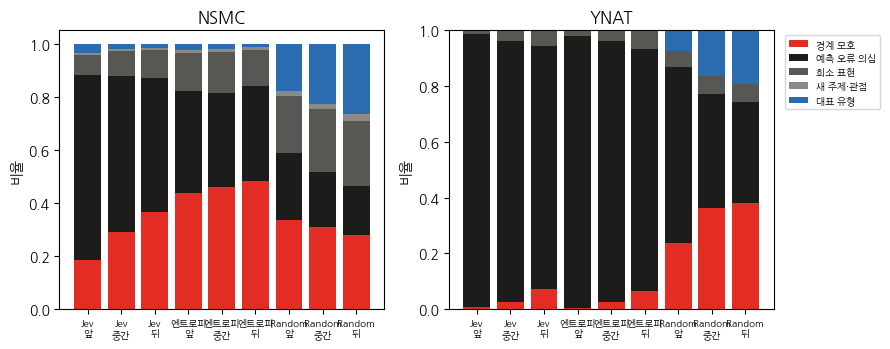

In [12]:
# ── 근거 유형 분포 ────
for name, lg in logs.items():
    print(f"\n{name} 최빈 근거 유형 비율")
    print(pd.crosstab(lg.strategy, lg.why, normalize="index").reindex(columns=WHY_NAMES).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
colors = [ACCENT, INK, GRAY, GRAY2, "#2B6CB0"]
for ax, (name, lg) in zip(axes, logs.items()):
    lg = lg.assign(phase=pd.cut(lg["round"], [-1, 12, 25, 37], labels=["앞", "중간", "뒤"]))
    tab = pd.crosstab([lg.strategy, lg.phase], lg.why, normalize="index").reindex(columns=WHY_NAMES).fillna(0)
    tab = tab.loc[[s for s in STRATS12 if s in tab.index.get_level_values(0)]]
    print(f"\n{name} 라운드 구간별 최빈 근거 유형 비율")
    print(tab.round(3).to_string())
    bottom = np.zeros(len(tab))
    for w, c in zip(WHY_NAMES, colors):
        ax.bar(range(len(tab)), tab[w], bottom=bottom, color=c, label=w, width=0.8)
        bottom += tab[w].values
    ax.set_xticks(range(len(tab)), [f"{s.split()[0]}\n{p}" for s, p in tab.index], fontsize=7)
    ax.set(title=name.upper(), ylabel="비율")
ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig("out/ch12_type_dist.png", dpi=200)

for name, lg in logs.items():
    d = DATA[name]
    print(f"\n{name} 근거 유형별 사례 ({BEST_NAME}, 시드 0)")
    for w in WHY_NAMES:
        for _, e in lg[(lg.strategy == BEST_NAME) & (lg.seed == 0) & (lg.why == w)].nlargest(1, f"w_{w}").iterrows():
            print(f"  {w:8s} {e[f'w_{w}']:.2f} | 정답 {LABEL_NAMES[name][int(e.y)]} 예측 {LABEL_NAMES[name][int(e.pred)]} | {str(d['texts'][int(e.idx)])[:40]}")

## 12.5 근거와 모델 개선량의 관계

라운드마다 고른 50개를 최빈 근거 유형별로 나눈다. 50개를 모두 더해 학습한 모델과 유형 τ에 속한 샘플만 빼고 학습한 모델의 시험 매크로 F1 차이 Δτ가 그 유형의 기여다. 유형마다 샘플 수가 다르므로 샘플 하나당 기여 Δτ / |Qτ|도 계산한다. 학생 모델이 가벼워서 라운드·유형마다 다시 학습할 수 있다. Jev 전략과 엔트로피의 선택을 대상으로 한다.


nsmc 근거 유형별 기여 (매크로 F1, per_sample은 샘플 하나당)
                   rounds    n_mean  delta_mean  per_sample
strategy why                                               
Jev 불일치  경계 모호        190  13.90526     0.00030     0.00002
         대표 유형        129   1.76744    -0.00026    -0.00015
         새 주제·관점       65   1.16923    -0.00046    -0.00040
         예측 오류 의심     190  29.97368     0.00130     0.00004
         희소 표현        188   4.56915    -0.00015    -0.00003
엔트로피     경계 모호        190  22.94211     0.00024     0.00001
         대표 유형        117   1.58974     0.00028     0.00018
         새 주제·관점       83   1.25301    -0.00010    -0.00008
         예측 오류 의심     190  18.30526     0.00233     0.00013
         희소 표현        190   7.22632    -0.00006    -0.00001



ynat 근거 유형별 기여 (매크로 F1, per_sample은 샘플 하나당)
                   rounds    n_mean  delta_mean  per_sample
strategy why                                               
Jev 불일치  경계 모호        121   2.58678     0.00020     0.00008
         대표 유형         10   1.00000    -0.00044    -0.00044
         새 주제·관점        2   1.00000     0.00124     0.00124
         예측 오류 의심     190  46.56316     0.01276     0.00027
         희소 표현        134   2.44776     0.00012     0.00005
엔트로피     경계 모호        104   2.73077     0.00033     0.00012
         대표 유형          9   1.11111     0.00016     0.00014
         새 주제·관점        1   1.00000    -0.00097    -0.00097
         예측 오류 의심     190  46.43684     0.01233     0.00027
         희소 표현        143   2.67133     0.00031     0.00012


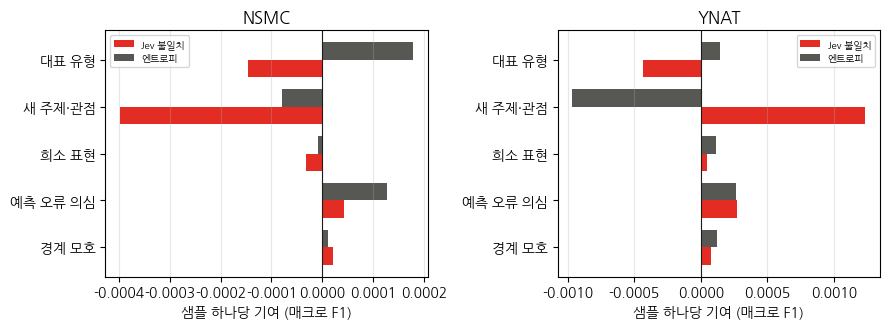

In [13]:
# ── 근거 유형별 빼기 기여 ────
def contrib_one(d, idx, lg, seed):
    rows = []
    y_test = d["y_test"]
    for r, g in lg.groupby("round"):
        base_l = idx[:N_INIT + r * K]
        Q = g.idx.values
        full = train_model(d["X_pool"][np.r_[base_l, Q]], d["y_pool"][np.r_[base_l, Q]], seed)
        f_full = f1_score(y_test, full.predict(d["X_test"]), average="macro")
        for w, gw in g.groupby("why"):
            keep = np.r_[base_l, Q[~np.isin(Q, gw.idx.values)]]
            m = train_model(d["X_pool"][keep], d["y_pool"][keep], seed)
            rows.append(dict(round=r, why=w, n=len(gw), delta=f_full - f1_score(y_test, m.predict(d["X_test"]), average="macro")))
    return pd.DataFrame(rows).assign(seed=seed)

contrib = {}
for name, d in DATA.items():
    jobs = [(s, sd) for s in (BEST_NAME, "엔트로피") for sd in SEEDS]
    out = Parallel(n_jobs=-1)(delayed(contrib_one)(d, orders[name][s, sd], logs[name][(logs[name].strategy == s) & (logs[name].seed == sd)], sd)
                              for s, sd in jobs)
    contrib[name] = pd.concat([o.assign(strategy=s) for (s, _), o in zip(jobs, out)], ignore_index=True)
    t = contrib[name].groupby(["strategy", "why"]).agg(rounds=("delta", "size"), n_mean=("n", "mean"), delta_mean=("delta", "mean"),
                                                       delta_sum=("delta", "sum"), n_sum=("n", "sum"))
    t["per_sample"] = t.delta_sum / t.n_sum
    print(f"\n{name} 근거 유형별 기여 (매크로 F1, per_sample은 샘플 하나당)")
    print(t.drop(columns=["delta_sum", "n_sum"]).round(5).to_string())

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (name, c) in zip(axes, contrib.items()):
    t = c.groupby(["strategy", "why"]).apply(lambda g: g.delta.sum() / g.n.sum(), include_groups=False).unstack(0).reindex(WHY_NAMES)
    t.plot.barh(ax=ax, color=[ACCENT, GRAY][:t.shape[1]], width=0.75)
    ax.axvline(0, color=INK, lw=0.8)
    ax.set(title=name.upper(), xlabel="샘플 하나당 기여 (매크로 F1)", ylabel="")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3, axis="x")
fig.tight_layout()
fig.savefig("out/ch12_contrib.png", dpi=200)

## 12.6 근거 기반 질의 감사

근거가 사실과 맞는지 점검할 수 있는 것만 감사한다.

- 「예측 오류 의심」: 학생 예측이 실제로 정답과 다른가
- Jev 라벨: 정답과 같은가(근거 유형별 정확도)
- 「경계 모호」: Jev 자신의 라벨 신뢰도가 실제로 낮은가

근거 유형별로 학생 예측 오류율, Jev 라벨 정확도, Jev 평균 신뢰도를 낸다. 마지막으로 「예측 오류 의심」인데 학생 예측이 맞았던 사례를 원문과 함께 본다.

In [14]:
# ── 근거 감사 ────
for name, lg in logs.items():
    a = lg.assign(pred_wrong=lg.pred != lg.y, jev_right=lg.jev_label == lg.y)
    t = a.groupby(["strategy", "why"]).agg(n=("idx", "size"), pred_wrong=("pred_wrong", "mean"), jev_acc=("jev_right", "mean"),
                                           jev_conf=("jev_conf", "mean"), pred_p=("pred_p", "mean")).round(4)
    print(f"\n{name} 근거 유형별 감사")
    print(t.to_string())
    print(f"{name} 전략 전체: 학생 예측 오류율", a.groupby("strategy").pred_wrong.mean().round(4).to_dict(),
          "| Jev 라벨 정확도", a.groupby("strategy").jev_right.mean().round(4).to_dict())

for name, lg in logs.items():
    d = DATA[name]
    bad = lg[(lg.strategy == BEST_NAME) & (lg.why == "예측 오류 의심") & (lg.pred == lg.y)]
    print(f"\n{name}: 「예측 오류 의심」인데 학생 예측이 맞은 사례 {len(bad)}개 중 일부")
    for _, e in bad.nlargest(4, "w_예측 오류 의심").iterrows():
        print(f"  {e['w_예측 오류 의심']:.2f} | 정답·예측 {LABEL_NAMES[name][int(e.y)]}({e.pred_p:.2f}) Jev {LABEL_NAMES[name][int(e.jev_label)]} | {str(d['texts'][int(e.idx)])[:40]}")


nsmc 근거 유형별 감사
                      n  pred_wrong  jev_acc  jev_conf  pred_p
strategy why                                                  
Jev 불일치  경계 모호     2642      0.1976   0.9402    0.9834  0.5016
         대표 유형      228      0.0175   0.9825    0.9997  0.5012
         새 주제·관점     76      0.1711   0.9474    0.9855  0.5014
         예측 오류 의심  5695      0.7666   0.9691    0.9938  0.5014
         희소 표현      859      0.2724   0.9464    0.9841  0.5015
Random   경계 모호     2938      0.1807   0.8598    0.9032  0.6274
         대표 유형     2127      0.0132   0.9868    0.9983  0.7786
         새 주제·관점    192      0.1458   0.8646    0.9381  0.6856
         예측 오류 의심  2036      0.7711   0.8610    0.9204  0.6161
         희소 표현     2207      0.1246   0.8971    0.9345  0.6972
엔트로피     경계 모호     4359      0.3583   0.8068    0.8656  0.5005
         대표 유형      186      0.0376   0.9624    0.9995  0.5004
         새 주제·관점    104      0.3654   0.7788    0.8923  0.5005
         예측 오류 의심  3478      0.7611   0


ynat 근거 유형별 감사
                      n  pred_wrong  jev_acc  jev_conf  pred_p
strategy why                                                  
Jev 불일치  경계 모호      313      0.2013   0.7764    0.8879  0.2262
         대표 유형       10      0.0000   0.8000    0.9120  0.2171
         새 주제·관점      2      0.5000   1.0000    0.8800  0.1851
         예측 오류 의심  8847      0.6878   0.7320    0.8814  0.1938
         희소 표현      328      0.2896   0.7348    0.8584  0.2121
Random   경계 모호     3083      0.1233   0.8245    0.8636  0.4870
         대표 유형     1359      0.0235   0.9706    0.9722  0.6909
         새 주제·관점      2      0.5000   1.0000    0.5650  0.3056
         예측 오류 의심  4481      0.5452   0.6996    0.8275  0.3011
         희소 표현      575      0.1096   0.9078    0.9280  0.4598
엔트로피     경계 모호      284      0.2148   0.7606    0.8341  0.2253
         대표 유형       10      0.1000   0.8000    0.8960  0.2379
         새 주제·관점      1      0.0000   1.0000    0.8000  0.1716
         예측 오류 의심  8823      0.6851   0

In [15]:
# ── 이 장이 쓴 Jev 입력 토큰 ────
import glob
files = [f for f in glob.glob("results/ch12_parts/*.csv") if not f.endswith(("_picks.csv", "_log.csv"))]
total = sum(pd.read_csv(f).filter(regex="^n_in").sum().sum() for f in files)
print(f"결과 파일에 기록된 Jev 입력 토큰 합: {total:,.0f}")

결과 파일에 기록된 Jev 입력 토큰 합: 23,689,618
